# Parte I. Transformación y construcción de la base relacional con Spark

**Integrantes:** Ricardo Acuña, Juan Aquino y Camilo Soto.

**Fuente:** Contrataciones Abiertas del Perú en estándar OCDS, publicadas por el OECE, antes OSCE, bajo licencia CC BY 4.0. Paquetes anuales 2023 a 2025 del [Registro de Datos de Open Contracting Partnership, publicación 135](https://data.open-contracting.org/es/publication/135).

**Dónde corre:** en Spark, de principio a fin, como exige el enunciado. La sesión es local y se abre con 2 GB y 3 hilos: la base cabe de sobra y así el notebook convive con otros trabajos de la máquina.

## Las preguntas que guían el proyecto

El primer proyecto dejó dos hechos que no se pueden ignorar: el gasto está muy concentrado y existe un suelo de procesos con un solo postor que atraviesa todos los tramos de monto. Este segundo proyecto deja de mirar procesos sueltos y mira **relaciones**, porque las preguntas que importan a quien supervisa el gasto público son relacionales.

1. **¿Qué tipos de proveedor existen y cuáles combinan dependencia de un solo cliente con poca competencia?** Un proveedor que vive de una sola entidad y gana sin rivales no es una falta, pero es justo el perfil que conviene mirar primero. Se responde con clustering en la Parte II.
2. **¿Es predecible con quién contrata una entidad, y qué relaciones se salen de lo esperable?** Si el mercado es muy inercial, una entidad que de pronto contrata a un proveedor que nada en su historia anticipa merece una segunda mirada. Se responde con sistemas de recomendación en la Parte III.
3. **¿Quiénes son los actores centrales y hay grupos de proveedores que compiten siempre entre sí?** Coincidir una y otra vez con los mismos rivales es una señal clásica de reparto de mercado. Se responde con análisis de enlaces y comunidades en las Partes IV y V.

Las tres son señales descriptivas para priorizar una revisión, nunca acusaciones.

## Qué produce este notebook

Los tres objetos que piden las demás partes, exportados a data/processed en Parquet: vectores de características de proveedores y entidades, la matriz de interacción entidad por proveedor y entidad por familia de ítems, y el grafo de coparticipación de proveedores.

In [1]:
import sys, time
from pathlib import Path

# Los ayudantes del proyecto viven en notebooks/scripts. Se importan por
# nombre, no con asterisco, para que quede claro de donde sale cada uno.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "notebooks" / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import Window
from pyspark.sql import functions as F

from helpers import (PARQUET, BASE, FIGS, ARTEFACTOS, FIGURAS, HALLAZGOS, PALETA,
                     AZUL, ROJO, VERDE, MORADO, TEAL, TINTA, SUAVE, REJILLA, fmt, MILES,
                     abrir_spark, cronometro, medir, figura, exportar, hallazgo,
                     barras_h, barras_agrupadas, mapa_calor)
import relacional as R
from ingesta import leer

pd.set_option("display.width", 190)
pd.set_option("display.max_colwidth", 64)


spark = abrir_spark("P2-I-Base")
procesos = spark.read.parquet(str(PARQUET))
print(f"{procesos.count():,} procesos limpios heredados del proyecto 1")
print(f"Spark {spark.version}, {spark.sparkContext.defaultParallelism} hilos, "
      f"{spark.conf.get('spark.sql.shuffle.partitions')} particiones de barajado")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/26 11:44:53 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


175,338 procesos limpios heredados del proyecto 1
Spark 4.2.0, 3 hilos, 8 particiones de barajado


**Versión de los datos.** El registro de Open Contracting republica los paquetes anuales, y la misma dirección puede devolver otro contenido de una semana a otra: entre dos descargas de octubre de 2026 cambió casi el uno por ciento de los procesos, y con ellos todas las cifras. Para que cada resultado se pueda atribuir a un dato concreto se guarda la fecha de descarga y la huella sha256 de cada paquete. Si una corrida futura da otra huella, los números pueden cambiar sin que haya cambiado el código.

In [2]:
import hashlib
from helpers import CRUDO
from ingesta import PERIODOS

def sha256(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()

version = []
for periodo in PERIODOS:
    paquete = CRUDO / f"{periodo}.csv.tar.gz"
    existe = paquete.exists()
    version.append({"paquete": paquete.name,
                    "descargado": (pd.Timestamp(paquete.stat().st_mtime, unit="s", tz="UTC").tz_convert("America/Lima")
                                   .strftime("%Y-%m-%d %H:%M") if existe else None),
                    "mb": round(paquete.stat().st_size / 1e6, 1) if existe else None,
                    "sha256": sha256(paquete) if existe else None})
version = pd.DataFrame(version)
exportar(version, "p1_version_datos", "Fecha de descarga y huella sha256 de cada paquete anual usado")
if version.sha256.isna().any():
    print("Falta algún paquete comprimido en", CRUDO, "y su huella no se puede registrar.")
else:
    print(f"Los resultados de este notebook corresponden a los paquetes descargados entre el "
          f"{version.descargado.min()} y el {version.descargado.max()}, hora de Lima.")
version

Los resultados de este notebook corresponden a los paquetes descargados entre el 2026-10-26 09:23 y el 2026-10-26 09:26, hora de Lima.


,paquete,descargado,mb,sha256
0,2023.csv.tar.gz,2026-10-26 09:23,71.4,358a5666a1cf1d8798f88146920eee1b356d5c5898def51ffa6c745d4ef0...
1,2024.csv.tar.gz,2026-10-26 09:25,166.0,8bbe5b4d6fa0f319e74ac9d52b167f537f74ea7cbdb43e0ee0b2f3d1f3f0...
2,2025.csv.tar.gz,2026-10-26 09:26,197.0,ee5c702e881054b461d5fe4cb7c440bc2c9919acd7089ea1feccf54bfd1d...


## 1. Del proceso a la relación

La tabla del proyecto 1 tiene una fila por proceso y guarda solo al proveedor de la adjudicación mayor. Eso bastaba para describir el gasto, pero no para construir relaciones: un proceso con cinco ítems adjudicados a cinco proveedores aparecía como una sola relación, y los postores que perdieron no aparecían en absoluto.

Por eso se vuelve a los CSV crudos solo para tres tablas, restringidas a los 177.398 procesos ya limpios:

1. **tender_tenderers**, los participantes de cada proceso. Es la materia prima del grafo de coparticipación.
2. **awards_suppliers** con **awards** y **contracts**, todos los proveedores adjudicados con su monto y si se firmó contrato.
3. **awards_items**, para saber qué familia del catálogo CUBSO compró cada adjudicación.

El grano resultante es **entidad, proveedor, familia de ítem**, que es exactamente el que pide el enunciado. Las dos tablas se escriben a Parquet una vez y se releen, para no volver a pagar la lectura de 3 GB de CSV en cada paso siguiente.

In [3]:
INTERMEDIO = BASE / "intermedio"
# Si el intermedio ya existe no se relee el crudo; borrar la carpeta fuerza la lectura.
# Tambien se rehace si la tabla del proyecto 1 es mas nueva: mezclaria datos de dos descargas.
listo = INTERMEDIO / "adjudicaciones" / "_SUCCESS"
if not listo.exists() or listo.stat().st_mtime < (PARQUET / "_SUCCESS").stat().st_mtime:
    with cronometro("lectura de CSV crudos y escritura en Parquet"):
        R.participaciones(spark, procesos).write.mode("overwrite").parquet(str(INTERMEDIO / "participaciones"))
        R.adjudicaciones(spark, procesos).write.mode("overwrite").parquet(str(INTERMEDIO / "adjudicaciones"))

part = spark.read.parquet(str(INTERMEDIO / "participaciones"))
adj = spark.read.parquet(str(INTERMEDIO / "adjudicaciones"))
n_part, n_adj = part.count(), adj.count()
procesos_adj = adj.select("ocid").distinct().count()
varios = adj.groupBy("ocid").agg(F.countDistinct("proveedor_id").alias("k")).filter("k > 1").count()
print(f"{n_part:,} participaciones y {n_adj:,} adjudicaciones en {procesos_adj:,} procesos")
print(f"{varios:,} procesos adjudicados a más de un proveedor, que la tabla por proceso reducía a uno")

2,221,884 participaciones y 154,591 adjudicaciones en 144,139 procesos
6,247 procesos adjudicados a más de un proveedor, que la tabla por proceso reducía a uno


## 2. Enlaces incompletos: qué cuenta como arista

La fuente advierte que hay adjudicaciones sin contrato vinculado y contratos sin adjudicación. Antes de decidir se mide cuánto pesa cada caso.


Lectura de f01_sin_contrato_metodo
La falta de contrato no se reparte al azar: en Concurso Público de Servicios llega al 17 por ciento de las adjudicaciones, mientras en el total es el 9.3 por ciento. Una adjudicación sin contrato publicado puede ser un contrato en trámite, una orden de compra que el sistema no enlaza o una adjudicación que no prosperó. Para las relaciones del proyecto la arista es la adjudicación, porque es el acto que decide a quién se le compra, y la falta de contrato queda como atributo de la arista. Los 1,169 contratos sin adjudicación se descartan: sin adjudicación no hay proveedor confiable al cual atribuirlos.



,caso,filas,pct
0,adjudicación con contrato,141150,90.7
1,adjudicación sin contrato,14484,9.3
2,contrato sin adjudicación,1169,0.8
3,adjudicación sin proveedor,1043,0.7


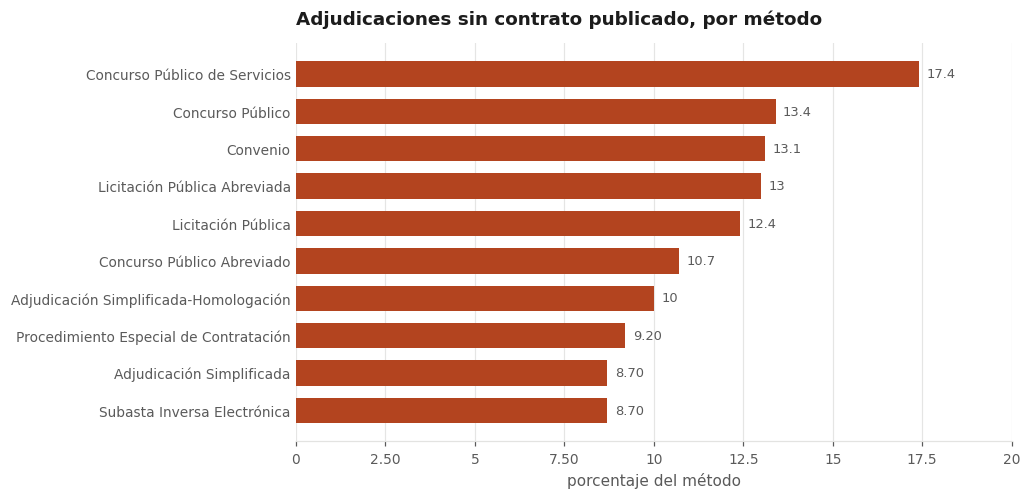

In [4]:
ocids = procesos.select("ocid")
premios = (leer(spark, "awards.csv", ["main_ocid", "id"])
           .select(F.col("main_ocid").alias("ocid"), F.col("id").alias("awards_id")).join(ocids, "ocid").distinct())
contratos = (leer(spark, "contracts.csv", ["main_ocid", "awardID"])
             .select(F.col("main_ocid").alias("ocid"), F.col("awardID").alias("awards_id")).join(ocids, "ocid").distinct())
con_proveedor = adj.select("ocid", "awards_id").distinct()

enlaces = pd.DataFrame([
    {"caso": "adjudicación con contrato", "filas": premios.join(contratos, ["ocid", "awards_id"]).count()},
    {"caso": "adjudicación sin contrato", "filas": premios.join(contratos, ["ocid", "awards_id"], "left_anti").count()},
    {"caso": "contrato sin adjudicación", "filas": contratos.join(premios, ["ocid", "awards_id"], "left_anti").count()},
    {"caso": "adjudicación sin proveedor", "filas": premios.join(con_proveedor, ["ocid", "awards_id"], "left_anti").count()},
])
enlaces["pct"] = (100 * enlaces.filas / premios.count()).round(1)
exportar(enlaces, "p1_enlaces", "Adjudicaciones y contratos con y sin su contraparte")

sin_contrato = (adj.groupBy("metodo").agg(F.count("*").alias("adjudicaciones"),
                                          F.avg((~F.col("con_contrato")).cast("double")).alias("pct"))
                .filter("adjudicaciones >= 300").toPandas())
sin_contrato["pct"] = (100 * sin_contrato.pct).round(1)
exportar(sin_contrato, "p1_sin_contrato_metodo", "Porcentaje de adjudicaciones sin contrato por metodo")

fig, ax = barras_h(sin_contrato.nlargest(10, "pct"), "metodo", "pct",
                   "Adjudicaciones sin contrato publicado, por método", "porcentaje del método", color=ROJO)
peor = sin_contrato.nlargest(1, "pct").iloc[0]
sc = enlaces.set_index("caso")
figura(fig, "f01_sin_contrato_metodo", f"""
La falta de contrato no se reparte al azar: en {peor.metodo} llega al {peor.pct:.0f} por ciento de las
adjudicaciones, mientras en el total es el {sc.loc['adjudicación sin contrato', 'pct']:.1f} por ciento.
Una adjudicación sin contrato publicado puede ser un contrato en trámite, una orden de compra que el
sistema no enlaza o una adjudicación que no prosperó. Para las relaciones del proyecto la arista es la
adjudicación, porque es el acto que decide a quién se le compra, y la falta de contrato queda como
atributo de la arista. Los {sc.loc['contrato sin adjudicación', 'filas']:,} contratos sin adjudicación
se descartan: sin adjudicación no hay proveedor confiable al cual atribuirlos.""")
enlaces

**Decisión.** La arista entidad a proveedor es la adjudicación, con o sin contrato. Descartar las adjudicaciones sin contrato borraría casi una de cada diez relaciones y lo haría de forma sesgada, porque se concentran en ciertos métodos. Conservarlas con la marca con_contrato permite a cualquier análisis posterior filtrarlas si su pregunta lo exige. Los contratos sin adjudicación son menos del uno por ciento y no tienen proveedor identificable.

## 3. Resolución de entidades

Si un mismo actor aparece con dos identificadores, el grafo lo parte en dos nodos, su grado se reparte y cualquier medida de centralidad o de dependencia sale falseada. Se revisa primero el lado comprador y después el proveedor.

### 3.1 Compradores

In [5]:
ruc_comprador = (leer(spark, "parties_additionalIdentifiers.csv", ["main_ocid", "id", "scheme", "parties_id"])
                 .filter("scheme = 'PE-RUC'")
                 .select(F.col("main_ocid").alias("ocid"), F.col("parties_id").alias("comprador_id"),
                         F.col("id").alias("ruc"))
                 .join(procesos.select("ocid", "comprador_id"), ["ocid", "comprador_id"]))
rucs_por_id = ruc_comprador.groupBy("comprador_id").agg(F.countDistinct("ruc").alias("k"))
ids_por_ruc = ruc_comprador.groupBy("ruc").agg(F.countDistinct("comprador_id").alias("k"))
homonimos = (procesos.groupBy("comprador_nombre").agg(F.countDistinct("comprador_id").alias("k"),
                                                      F.collect_set("departamento").alias("deptos"))
             .filter("k > 1").toPandas())
print(f"compradores: {procesos.select('comprador_id').distinct().count():,}")
print(f"identificadores con más de un RUC: {rucs_por_id.filter('k > 1').count()}")
print(f"RUC con más de un identificador:   {ids_por_ruc.filter('k > 1').count()}")
homonimos

compradores: 2,968


identificadores con más de un RUC: 0


RUC con más de un identificador:   0


,comprador_nombre,k,deptos
0,MUNICIPALIDAD DISTRITAL DE MARISCAL CACERES,2,"[HUANCAVELICA, AREQUIPA]"
1,MUNICIPALIDAD DISTRITAL DE SAN MIGUEL,2,"[PUNO, LIMA]"


El lado comprador está limpio: cada identificador del catálogo de entidades corresponde a un único RUC y viceversa. Los dos nombres repetidos son municipalidades distritales homónimas de provincias distintas, es decir dos entidades reales con el mismo nombre, y fusionarlas sería un error. **No se toca el identificador del comprador.**

### 3.2 Proveedores

Aquí está el problema que advierte la fuente. Todos los identificadores llevan el prefijo PE-RUC, pero no todos son un RUC.

In [6]:
dep = procesos.select("ocid", "departamento")
registros = (part.select("ocid", "proveedor_id", "proveedor_nombre")
             .unionByName(adj.select("ocid", "proveedor_id", "proveedor_nombre"))
             .join(dep, "ocid"))
claves = R.claves_exactas(registros).cache()

por_tipo = (claves.groupBy("tipo").agg(F.count("*").alias("identificadores"),
                                       F.countDistinct("clave").alias("claves_exactas")).toPandas()
            .sort_values("identificadores", ascending=False))
por_tipo

,tipo,identificadores,claves_exactas
1,consorcio,103722,51292
2,empresa,70918,70918
0,persona natural,31860,31860
3,extranjero,2707,2094


Cuatro tipos de identificador, con un tratamiento distinto cada uno:

1. **Empresa y persona natural** tienen RUC de 11 dígitos. El RUC es la identidad legal y basta: si el nombre cambia entre registros, como COMPAÑIA DE SEGURIDAD PROSEGUR S. A y CIA DE SEGURIDAD PROSEGUR S A, sigue siendo el mismo contribuyente.
2. **Extranjeros** no tienen RUC y reciben un código distinto en casi cada proceso. Su nombre sí es distintivo, así que la clave es el nombre normalizado, sin tildes, puntuación ni forma jurídica.
3. **Consorcios** reciben un código interno nuevo por inscripción. Son la mitad de los identificadores y el caso delicado, porque el nombre no es único: hay más de 160 consorcios distintos llamados Santa Rosa en el país. La clave es el nombre normalizado más el departamento donde opera.

Ese tercer criterio es una hipótesis y se valida con el propio dato: **dos códigos que participaron en el mismo proceso son, con certeza, dos proveedores distintos**, porque nadie compite contra sí mismo. Si una clave agrupa códigos rivales, esa clave no se fusiona.

In [7]:
rivales = R.conflictos(part, claves.select("proveedor_id", "clave")).cache()
n_rivales = rivales.count()
codigos_rivales = claves.join(rivales, "clave").count()

# Las claves con codigos rivales vuelven al identificador original.
claves = (claves.join(rivales.withColumn("rival", F.lit(True)), "clave", "left")
          .withColumn("clave", F.when(F.col("rival"), F.concat(F.lit("ID-"), "proveedor_id"))
                                .otherwise(F.col("clave")))
          .drop("rival").cache())
print(f"{n_rivales:,} claves por nombre y departamento agrupaban {codigos_rivales:,} códigos "
      f"que compitieron entre sí; no se fusionan")

1,603 claves por nombre y departamento agrupaban 12,301 códigos que compitieron entre sí; no se fusionan


El segundo paso son los nombres casi iguales, que la clave exacta no ve: CONSORCIO SUPERVISOR VILLAREAL y CONSORCIO SUPERVISOR VILLARREAL, o FRANCO SANTOS TANIA CRISTINA y TANIA CRISTINA FRANCO SANTOS. Se reutiliza el método de la Parte II del proyecto 1, escrito con DataFrames de Spark: tejas de 3 caracteres, firma MinHash de 40 funciones y LSH con 10 bandas de 4 filas, y cada candidato se verifica con su Jaccard exacto.

**Por qué no el MinHashLSH de MLlib.** Se probó primero y no terminó en veinte minutos. Sus bandas tienen una sola fila, de modo que dos nombres son candidatos si coinciden en un solo mínimo de entre seis; como casi todos los consorcios comparten las tejas de la palabra CONSORCIO, casi todos los pares chocaban en algún balde. Con 4 filas por banda el umbral de la curva S sube a 0,56 y un par con Jaccard 0,85 sigue siendo candidato con probabilidad mayor a 0,999. Es la misma lección del proyecto 1: el número de filas por banda es lo que hace selectivo a LSH.

Dos reglas más, ambas por errores vistos en una primera pasada: las palabras se ordenan antes de formar tejas, y los números y romanos deben coincidir, porque CONSORCIO VIAL AN 104 y CONSORCIO VIAL AN 107 son dos consorcios distintos aunque su Jaccard sea 0,8. Cuentan los romanos sueltos hasta XXXIX y los números sueltos o pegados al final de una palabra, como en CONSORCIO CCARHUAYO1, que la regla anterior, solo con números sueltos, fusionaba con CONSORCIO CCARHUAYO.

In [8]:
with cronometro("MinHash y LSH sobre nombres sin RUC"):
    pares = R.pares_difusos(claves).cache()
    n_candidatos = pares.count()
fusionables = pares.filter("fusiona")
mapa = R.unir([(r.a, r.b) for r in fusionables.select("a", "b").collect()])
mapa_df = spark.createDataFrame(list(mapa.items()), ["clave", "clave_final"])
propuesta = (claves.join(mapa_df, "clave", "left")
             .withColumn("clave_final", F.coalesce("clave_final", "clave")))

# La misma validacion: un grupo difuso que junte rivales se deshace.
rivales_difusos = R.conflictos(part, propuesta.select("proveedor_id", F.col("clave_final").alias("clave")))
propuesta = (propuesta.join(rivales_difusos.select(F.col("clave").alias("clave_final"))
                            .withColumn("rival", F.lit(True)), "clave_final", "left")
             .withColumn("clave_final", F.when(F.col("rival"), F.col("clave")).otherwise(F.col("clave_final")))
             .drop("rival"))
print(f"{n_candidatos:,} pares candidatos, {fusionables.count():,} con Jaccard de al menos 0,85, "
      f"{rivales_difusos.count():,} grupos deshechos por rivalidad")
ejemplos = (fusionables.orderBy(F.rand(7)).limit(12)
            .select("nombre_a", "nombre_b", F.round("jaccard", 2).alias("jaccard")).toPandas())
exportar(ejemplos, "p1_ejemplos_fusion", "Muestra de nombres fusionados por MinHash y LSH")
ejemplos

MinHash y LSH sobre nombres sin RUC: 42.73 s


133,796 pares candidatos, 1,396 con Jaccard de al menos 0,85, 82 grupos deshechos por rivalidad


,nombre_a,nombre_b,jaccard
0,CONSORCIO CORPORACION GRECIA SOLUCIONES INTEGRALES Y SYT SOL...,CORPORACION GRECIA SOLUCIONES INTEGRALES Y SYT SOLUTION SEND...,1.00
1,CONSORCIO PACIFICO CONFORMADO POR PACIFICO COMPANIA DE SEGUR...,CONSORCIO PACIFICO CONFORMADO POR PACIFICO COMPANIA DE SEGUR...,0.90
2,CONSORCIO TABACONAS,TABACONAS,1.00
3,CONSORCIO FMR ELECTRIC,FMR ELECTRIC,1.00
4,CONSORCIO MAGOYA,MAGOYA,1.00
5,CONSORCIO PONTO VIEJO,CONSORCIO VIEJO PONTO,1.00
6,BICENTENARIO,CONSORCIO BICENTENARIO,1.00
7,CONSORCIO NUEVA ESPERANZA,NUEVA ESPERANZA,1.00
8,CONSORCIO QUEROBAMBA,QUEROBAMBA,1.00
9,CONSORCIO ENERSYS,ENERSYS,1.00


**Precisión de la fusión difusa.** La regla de rivalidad solo detecta fusiones falsas entre códigos que compitieron entre sí; dos consorcios distintos que nunca coincidieron en un proceso pasarían sin ser detectados. Para medir la precisión se toma una muestra estratificada de 25 pares candidatos por tramo de Jaccard, dos tramos por debajo del umbral de 0,85 y dos por encima, y se etiqueta a mano si los dos nombres son el mismo proveedor. Sobre el umbral, la fracción de pares que sí lo son es la precisión de la fusión; debajo, es lo que el umbral deja sin fusionar.

La muestra se guarda una sola vez en etiquetas/pares_resolucion.csv, en la carpeta del proyecto, para que las etiquetas no se pierdan al volver a correr el notebook. Para etiquetar se llena la columna mismo_proveedor con 1 si los dos nombres son el mismo proveedor y con 0 si no; ante la duda se pone 0 y se explica en la columna nota. La precisión se calcula sola cuando no quedan pares sin etiquetar.

In [9]:
ETIQUETAS = RAIZ / "etiquetas" / "pares_resolucion.csv"
if not ETIQUETAS.exists():
    candidatos = pares.filter("jaccard >= 0.70").select("a", "b", "nombre_a", "nombre_b", "jaccard").toPandas()
    candidatos["tramo"] = pd.cut(candidatos.jaccard, [.70, .80, .85, .90, 1.0001], right=False,
                                 labels=["0,70 a 0,80", "0,80 a 0,85", "0,85 a 0,90", "0,90 o más"])
    muestra = candidatos.sample(frac=1, random_state=7).groupby("tramo", observed=True).head(25).sort_values("jaccard")
    muestra = muestra.assign(jaccard=muestra.jaccard.round(3), fusionado=muestra.jaccard >= .85,
                             mismo_proveedor=None, nota=None)
    ETIQUETAS.parent.mkdir(exist_ok=True)
    muestra[["tramo", "jaccard", "fusionado", "nombre_a", "nombre_b", "a", "b", "mismo_proveedor", "nota"]
            ].to_csv(ETIQUETAS, index=False)
    print(f"Muestra de {len(muestra)} pares guardada en {ETIQUETAS.relative_to(RAIZ)}.")

etiquetas = pd.read_csv(ETIQUETAS)
faltan = int(etiquetas.mismo_proveedor.isna().sum())
if faltan:
    print(f"Faltan {faltan} de {len(etiquetas)} pares por etiquetar; la precisión se calcula cuando estén todos.")
    resumen_et = etiquetas.groupby("tramo").size().rename("pares_en_la_muestra").to_frame()
else:
    resumen_et = etiquetas.groupby("tramo").agg(pares=("mismo_proveedor", "size"),
                                                mismo_proveedor=("mismo_proveedor", "sum"))
    resumen_et["pct_mismo_proveedor"] = (100 * resumen_et.mismo_proveedor / resumen_et.pares).round(1)
    exportar(resumen_et.reset_index(), "p1_precision_resolucion", "Fraccion de pares que son el mismo proveedor, por tramo de Jaccard")
    precision = etiquetas[etiquetas.fusionado].mismo_proveedor.mean()
    omitidos = etiquetas[~etiquetas.fusionado].mismo_proveedor.mean()
    print(f"De los pares fusionados de la muestra, el {100*precision:.0f} por ciento es de verdad el mismo "
          f"proveedor: esa es la precisión de la fusión difusa. Entre los pares que el umbral deja sin "
          f"fusionar, el {100*omitidos:.0f} por ciento también lo era, y es lo que se pierde por ser prudente.")
resumen_et

Faltan 100 de 100 pares por etiquetar; la precisión se calcula cuando estén todos.


,pares_en_la_muestra
tramo,
"0,70 a 0,80",25
"0,80 a 0,85",25
"0,85 a 0,90",25
"0,90 o más",25



Lectura de f02_resolucion
Los consorcios explican casi toda la fragmentación: 103,722 códigos publicados corresponden a 60,776 consorcios, una reducción del 41 por ciento, mientras que empresas y personas naturales ya venían con un identificador único por RUC. En total 209,207 identificadores pasan a 165,615 proveedores. Sin este paso, un consorcio que gana diez obras en un departamento aparecería como diez proveedores de una obra cada uno, y en el grafo como diez nodos sueltos: justo el patrón de concentración que se quiere detectar quedaría escondido por un artefacto de registro.



,tipo,identificadores,proveedores,claves_exactas,reduccion_pct
1,consorcio,103722,60776,51292,41.4
3,empresa,70918,70918,70918,0.0
0,persona natural,31860,31860,31860,0.0
2,extranjero,2707,2061,2094,23.9


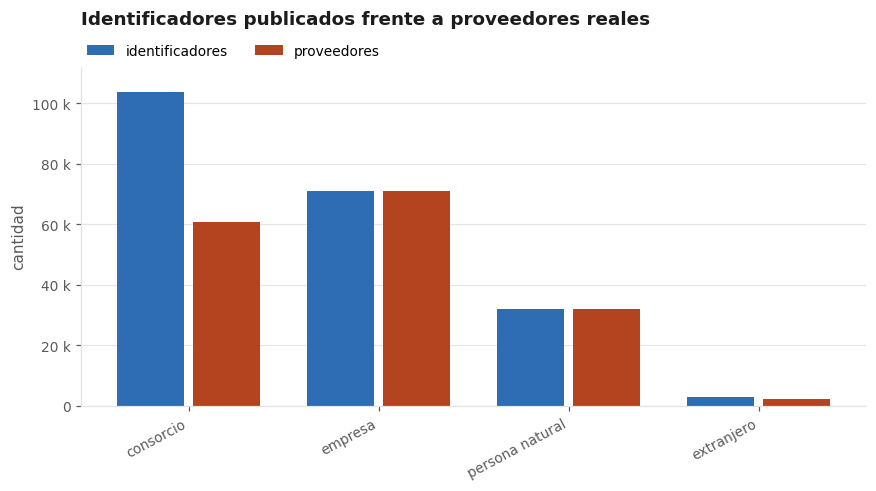

In [10]:
# Nombre canonico: el mas frecuente entre los registros de la clave final.
orden = Window.partitionBy("clave").orderBy(F.col("n").desc(), "proveedor_nombre")
nombres = (registros.join(propuesta.select("proveedor_id", F.col("clave_final").alias("clave")), "proveedor_id")
           .groupBy("clave", "proveedor_nombre").agg(F.count("*").alias("n"))
           .withColumn("_r", F.row_number().over(orden)).filter("_r = 1")
           .select("clave", F.col("proveedor_nombre").alias("nombre")))
mapa_proveedores = (propuesta.select("proveedor_id", "tipo", F.col("clave_final").alias("clave"))
                    .join(nombres, "clave")
                    .withColumn("nodo", F.xxhash64("clave")))
mapa_proveedores.write.mode("overwrite").parquet(str(BASE / "mapa_proveedores"))
mapa_proveedores = spark.read.parquet(str(BASE / "mapa_proveedores"))

resol = (mapa_proveedores.groupBy("tipo").agg(F.count("*").alias("identificadores"),
                                              F.countDistinct("clave").alias("proveedores"))
         .toPandas().merge(por_tipo[["tipo", "claves_exactas"]], on="tipo")
         .sort_values("identificadores", ascending=False))
resol["reduccion_pct"] = (100 * (1 - resol.proveedores / resol.identificadores)).round(1)
exportar(resol, "p1_resolucion", "Identificadores publicados frente a proveedores resueltos, por tipo")

fig, ax = barras_agrupadas(resol, "tipo", ["identificadores", "proveedores"],
                           "Identificadores publicados frente a proveedores reales", "cantidad")
con = resol.set_index("tipo").loc["consorcio"]
total_ids, total_prov = resol.identificadores.sum(), resol.proveedores.sum()
figura(fig, "f02_resolucion", f"""
Los consorcios explican casi toda la fragmentación: {int(con.identificadores):,} códigos publicados
corresponden a {int(con.proveedores):,} consorcios, una reducción del {con.reduccion_pct:.0f} por ciento,
mientras que empresas y personas naturales ya venían con un identificador único por RUC. En total
{total_ids:,} identificadores pasan a {total_prov:,} proveedores. Sin este paso, un consorcio que
gana diez obras en un departamento aparecería como diez proveedores de una obra cada uno, y en el
grafo como diez nodos sueltos: justo el patrón de concentración que se quiere detectar quedaría
escondido por un artefacto de registro.""")
resol

In [11]:
hallazgo("I", "La mitad de los identificadores de proveedor son códigos de consorcio, y muchos repetidos",
         f"""De {total_ids:,} identificadores publicados quedan {total_prov:,} proveedores reales. La
         fragmentación vive casi entera en los consorcios, que reciben un código nuevo por inscripción:
         {int(con.identificadores):,} códigos son {int(con.proveedores):,} consorcios. Cualquier ranking de
         proveedores o medida de concentración hecha sobre el identificador crudo subestima a quienes
         operan en consorcio.""",
         """Que el OECE asigne a cada consorcio un identificador estable vinculado a los RUC de sus
         integrantes, y que todo tablero de concentración use la clave resuelta y no el código
         publicado.""",
         "f02_resolucion, p1_resolucion")


HALLAZGO. La mitad de los identificadores de proveedor son códigos de consorcio, y muchos repetidos
De 209,207 identificadores publicados quedan 165,615 proveedores reales. La fragmentación vive casi entera en los consorcios, que reciben un código nuevo por inscripción: 103,722 códigos son 60,776 consorcios. Cualquier ranking de proveedores o medida de concentración hecha sobre el identificador crudo subestima a quienes operan en consorcio.
Accion propuesta: Que el OECE asigne a cada consorcio un identificador estable vinculado a los RUC de sus integrantes, y que todo tablero de concentración use la clave resuelta y no el código publicado.



## 4. La tabla de hechos

Una fila por adjudicación y proveedor resuelto, con la entidad, la familia CUBSO de su ítem principal, el monto en soles y el contexto del proceso. Es el grano entidad, proveedor, ítem del que salen los tres objetos.

La familia son los cuatro primeros dígitos del código CUBSO: 368 familias en la ventana, frente a 4.664 productos de ocho dígitos. Es la granularidad de un mercado, por ejemplo medicamentos o maquinaria de construcción, y no la de un producto.

El monto es el adjudicado. En el 2 por ciento de adjudicaciones en moneda extranjera se convierte con el tipo de cambio que la fuente publica para cada adjudicación, y las pocas sin tipo publicado usan la mediana de su moneda. No se usa el valor referencial en soles del proceso: es de todo el proceso, y en uno con varios proveedores se le acreditaría completo a cada uno. Se escribe particionado por año, lo que la sección 8 aprovecha.

In [12]:
tasa = (leer(spark, "awards_value_exchangeRates.csv", ["main_ocid", "awards_id", "rate", "currency"])
        .filter("currency = 'PEN'")
        .select(F.col("main_ocid").alias("ocid"), "awards_id", F.col("rate").cast("double").alias("tasa"))
        .dropDuplicates(["ocid", "awards_id"]))
adj_soles = adj.join(tasa, ["ocid", "awards_id"], "left")
tasa_moneda = adj_soles.groupBy("moneda_adjudicada").agg(F.expr("percentile_approx(tasa, 0.5)").alias("tasa_moneda"))
hechos = (adj_soles.join(tasa_moneda, "moneda_adjudicada", "left")
          .join(mapa_proveedores.select("proveedor_id", "clave", "tipo", "nodo"), "proveedor_id")
          .withColumn("monto", F.when(F.col("moneda_adjudicada") == "PEN", F.col("monto_adjudicado"))
                                 .otherwise(F.col("monto_adjudicado") * F.coalesce("tasa", "tasa_moneda")))
          .select("ocid", "awards_id", "comprador_id", "clave", "nodo", "tipo", "familia", "monto",
                  "fecha", "anio", "anio_mes", "metodo", "categoria", "n_postores", "departamento",
                  "nivel_gobierno", "con_contrato"))
with cronometro("escritura de la tabla de hechos particionada por año"):
    hechos.write.mode("overwrite").partitionBy("anio").parquet(str(BASE / "hechos"))
hechos = spark.read.parquet(str(BASE / "hechos")).cache()
part_r = (part.join(mapa_proveedores.select("proveedor_id", "clave", "nodo"), "proveedor_id")
          .select("ocid", "clave", "nodo").dropDuplicates())
part_r.write.mode("overwrite").parquet(str(BASE / "participaciones"))
part_r = spark.read.parquet(str(BASE / "participaciones")).cache()
print(f"hechos: {hechos.count():,} filas, participaciones resueltas: {part_r.count():,}")
hechos.limit(3).toPandas()

escritura de la tabla de hechos particionada por año: 4.28 s


hechos: 154,591 filas, participaciones resueltas: 2,221,884


,ocid,awards_id,comprador_id,clave,nodo,tipo,familia,monto,fecha,anio_mes,metodo,categoria,n_postores,departamento,nivel_gobierno,con_contrato,anio
0,ocds-dgv273-seacev3-1001019,1001019-1507086,PE-CONSUCODE-2378,CON-M M NAZ|LAMBAYEQUE,1306452625532814354,consorcio,None,910200.0,2023-12-21 15:50:00,2023-12,Adjudicación Simplificada,goods,17.0,LAMBAYEQUE,Empresa del Estado,True,2023
1,ocds-dgv273-seacev3-1002391,1002391-1508291,PE-CONSUCODE-10042,CON-ORIENT|CUSCO,-6886296677617736865,consorcio,1111,5125155.0,2023-12-28 21:24:00,2023-12,Licitación Pública,goods,29.0,CUSCO,Gobierno regional,False,2023
2,ocds-dgv273-seacev3-1002816,1002816-20602186793,PE-CONSUCODE-10352,RUC-20602186793,-5407846960725872518,empresa,7212,278000.0,2023-11-22 20:43:00,2023-11,Adjudicación Simplificada,services,13.0,PIURA,Gobierno regional,False,2023


## 5. Vectores de características

Un vector por proveedor y otro por entidad. Cada característica está elegida porque responde una pregunta distinta sobre el comportamiento, no porque esté disponible.

| Característica del proveedor | Qué mide |
| --- | --- |
| n_ganados, monto_total, monto_mediano | Escala: cuánto vende y de qué tamaño son sus contratos |
| n_entidades, n_departamentos | Alcance: a cuántos clientes y en cuántas regiones |
| cuota_cliente_top | Dependencia: qué parte de su monto viene de su mayor cliente |
| n_familias | Especialización: cuántos mercados distintos atiende |
| meses_activos | Continuidad en el período |
| tasa_victoria, n_participaciones | Éxito competitivo: cuántas de las veces que se presenta gana |
| pct_postor_unico, pct_sin_concurso | Competencia: cuánto de lo que gana lo gana sin rivales o sin concurso |
| pct_obras, pct_servicios | Rubro dominante |
| pct_sin_contrato | Calidad del enlace de sus adjudicaciones |

Para la entidad se guardan volumen, número de proveedores, concentración de su gasto con el índice de Herfindahl, postores medios, porcentaje con un solo postor y sin concurso, y variedad de familias. La estandarización y la elección final de variables se deciden en la Parte II, que es donde se usan; aquí se guardan en su escala natural para que sean interpretables.

In [13]:
feat_prov = (R.caracteristicas_proveedores(hechos, part_r)
             .join(mapa_proveedores.select("clave", "nodo", "tipo", "nombre").dropDuplicates(["clave"]), "clave"))
feat_ent = R.caracteristicas_entidades(hechos, procesos)
feat_prov.write.mode("overwrite").parquet(str(BASE / "caracteristicas_proveedores"))
feat_ent.write.mode("overwrite").parquet(str(BASE / "caracteristicas_entidades"))
feat_prov = spark.read.parquet(str(BASE / "caracteristicas_proveedores"))
fp = spark.read.parquet(str(BASE / "caracteristicas_proveedores")).toPandas()
fe = spark.read.parquet(str(BASE / "caracteristicas_entidades")).toPandas()
print(f"{len(fp):,} proveedores con al menos una adjudicación y {len(fe):,} entidades")
fp.describe().T[["mean", "50%", "max"]].round(2)

62,462 proveedores con al menos una adjudicación y 2,968 entidades


,mean,50%,max
n_ganados,2.470000e+00,1.000000e+00,1.457000e+03
monto_total,2.137544e+06,2.750000e+05,1.111909e+09
monto_mediano,1.146386e+06,1.445192e+05,1.111909e+09
n_entidades,1.700000e+00,1.000000e+00,2.610000e+02
n_departamentos,1.200000e+00,1.000000e+00,2.200000e+01
n_familias,1.220000e+00,1.000000e+00,2.100000e+01
meses_activos,1.940000e+00,1.000000e+00,3.500000e+01
pct_postor_unico,1.400000e-01,0.000000e+00,1.000000e+00
pct_sin_concurso,1.800000e-01,0.000000e+00,1.000000e+00
pct_obras,1.600000e-01,0.000000e+00,1.000000e+00



Lectura de f03_rasgos_proveedor
El proveedor típico del Estado es pequeño y de un solo cliente: el 79 por ciento de los 62,462 proveedores con alguna adjudicación le vendió a una sola entidad en tres años, y la mediana de adjudicaciones es 1. La cuota del mayor cliente se amontona en 1, y no por casualidad: es lo que pasa cuando se gana una sola vez. Por eso la dependencia solo es informativa entre recurrentes. Entre los 12,062 proveedores con tres o más adjudicaciones, 4,202 obtienen al menos el 80 por ciento de su monto de una sola entidad. Ese grupo es el punto de partida de la pregunta 1 y la Parte II lo caracteriza.



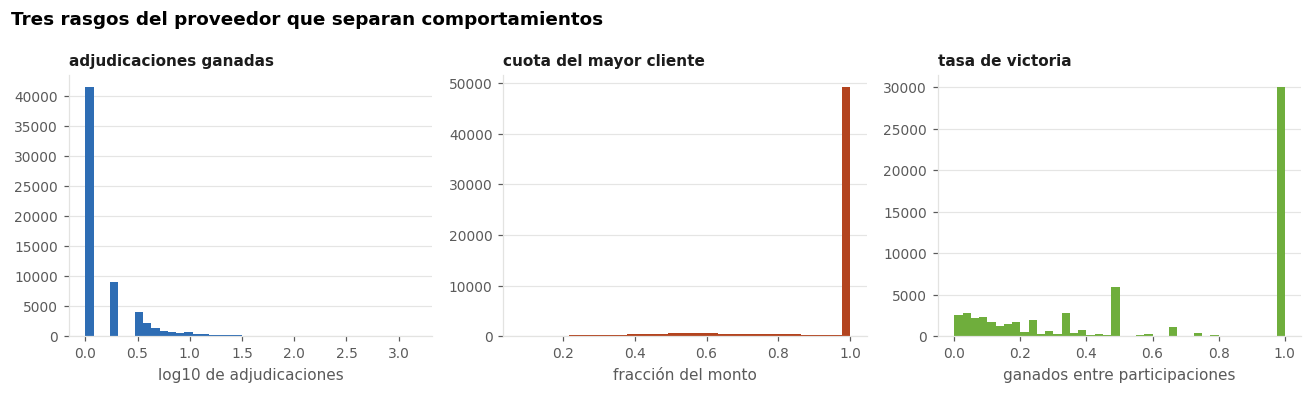

In [14]:
cliente_unico = fp.n_entidades.eq(1).mean()
recurrentes = fp[fp.n_ganados >= 3]
cautivos = recurrentes[(recurrentes.cuota_cliente_top >= .8)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (col, titulo, color) in zip(axes, [
        ("n_ganados", "adjudicaciones ganadas", AZUL),
        ("cuota_cliente_top", "cuota del mayor cliente", ROJO),
        ("tasa_victoria", "tasa de victoria", VERDE)]):
    datos = np.log10(fp[col]) if col == "n_ganados" else fp[col]
    ax.hist(datos, bins=40, color=color)
    ax.set_title(titulo, loc="left", fontsize=10); ax.grid(axis="y", alpha=.9); ax.set_axisbelow(True)
axes[0].set_xlabel("log10 de adjudicaciones"); axes[1].set_xlabel("fracción del monto"); axes[2].set_xlabel("ganados entre participaciones")
fig.suptitle("Tres rasgos del proveedor que separan comportamientos", x=.01, ha="left", fontweight="bold")
fig.tight_layout()
figura(fig, "f03_rasgos_proveedor", f"""
El proveedor típico del Estado es pequeño y de un solo cliente: el {100*cliente_unico:.0f} por ciento
de los {len(fp):,} proveedores con alguna adjudicación le vendió a una sola entidad en tres años, y la
mediana de adjudicaciones es {fp.n_ganados.median():.0f}. La cuota del mayor cliente se amontona en
1, y no por casualidad: es lo que pasa cuando se gana una sola vez. Por eso la dependencia solo es
informativa entre recurrentes. Entre los {len(recurrentes):,} proveedores con tres o más
adjudicaciones, {len(cautivos):,} obtienen al menos el 80 por ciento de su monto de una sola entidad.
Ese grupo es el punto de partida de la pregunta 1 y la Parte II lo caracteriza.""")

## 6. Matrices de interacción

Dos matrices dispersas en formato largo, una fila por celda no vacía y por año:

1. **Entidad por proveedor**, con el número de adjudicaciones como señal implícita y el monto como señal alternativa. Es la que usa la Parte III.
2. **Entidad por familia CUBSO**, que describe qué compra cada entidad. Sirve como perfil de contenido en la Parte III y como base de la SVD en la Parte VI.

Se guarda el año para poder evaluar la recomendación con una partición temporal, que es la única honesta: entrenar con el pasado y predecir el futuro.

In [15]:
inter_ep = R.interaccion(hechos, "comprador_id", "clave")
inter_ef = R.interaccion(hechos, "comprador_id", "familia")
inter_ep.write.mode("overwrite").parquet(str(BASE / "interaccion_entidad_proveedor"))
inter_ef.write.mode("overwrite").parquet(str(BASE / "interaccion_entidad_familia"))
ep = spark.read.parquet(str(BASE / "interaccion_entidad_proveedor"))
ef = spark.read.parquet(str(BASE / "interaccion_entidad_familia"))

total_ep = ep.groupBy("comprador_id", "clave").agg(F.sum("n").alias("n")).toPandas()
n_e, n_p = total_ep.comprador_id.nunique(), total_ep.clave.nunique()
densidad = len(total_ep) / (n_e * n_p)
total_ef = ef.groupBy("comprador_id", "familia").agg(F.sum("n").alias("n")).toPandas()
densidad_ef = len(total_ef) / (total_ef.comprador_id.nunique() * total_ef.familia.nunique())

# Persistencia: de los pares activos en 2025, cuantos ya existian antes.
anios = ep.groupBy("comprador_id", "clave").agg(F.min("anio").alias("desde"), F.max("anio").alias("hasta"),
                                               F.collect_set("anio").alias("anios")).toPandas()
activos_25 = anios[anios.anios.apply(lambda a: 2025 in a)]
repetidos = (activos_25.desde < 2025).mean()
# Las mismas relaciones pesadas por adjudicaciones y por monto de 2025.
ep25 = ep.filter("anio = 2025").toPandas().merge(activos_25[["comprador_id", "clave", "desde"]],
                                                 on=["comprador_id", "clave"])
rep_adj = ep25[ep25.desde < 2025].n.sum() / ep25.n.sum()
rep_monto = ep25[ep25.desde < 2025].monto.sum() / ep25.monto.sum()
resumen_m = pd.DataFrame([
    {"matriz": "entidad x proveedor", "filas": n_e, "columnas": n_p, "celdas": len(total_ep),
     "densidad_pct": round(100 * densidad, 4)},
    {"matriz": "entidad x familia", "filas": total_ef.comprador_id.nunique(),
     "columnas": total_ef.familia.nunique(), "celdas": len(total_ef), "densidad_pct": round(100 * densidad_ef, 2)}])
exportar(resumen_m, "p1_matrices", "Tamano y densidad de las dos matrices de interaccion")
print(f"de los {len(activos_25):,} pares entidad y proveedor activos en 2025, "
      f"el {100*repetidos:.1f} % ya había contratado en 2023 o 2024; "
      f"pesan el {100*rep_adj:.1f} % de las adjudicaciones y el {100*rep_monto:.1f} % del monto")
resumen_m

de los 37,223 pares entidad y proveedor activos en 2025, el 26.1 % ya había contratado en 2023 o 2024; pesan el 32.1 % de las adjudicaciones y el 17.1 % del monto


,matriz,filas,columnas,celdas,densidad_pct
0,entidad x proveedor,2964,62462,106446,0.0575
1,entidad x familia,2954,368,35262,3.2400



Lectura de f04_grados_interaccion
La matriz entidad por proveedor tiene 2,964 entidades, 62,462 proveedores y apenas 0.057 por ciento de celdas llenas. Las dos colas son largas, pero no iguales: la mediana de entidades por proveedor es 1, mientras una entidad mediana trabaja con 16 proveedores, y el 10 por ciento de entidades con más proveedores reúne el 49 por ciento de las relaciones. Para la recomendación esto significa que los proveedores son la dimensión difícil: la mayoría tiene una sola entidad de historia, de modo que el filtrado colaborativo puro no podrá decir nada de ellos y hace falta un perfil de contenido. Y solo el 26 por ciento de las relaciones activas en 2025 ya existía antes: repetir el pasado no basta para anticipar el mercado, que es justo el trabajo de un recomendador.



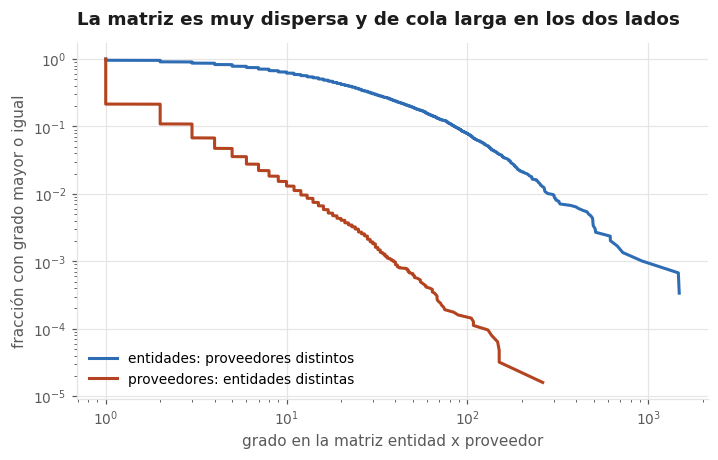

In [16]:
grado_e = total_ep.groupby("comprador_id").size().sort_values(ascending=False).values
grado_p = total_ep.groupby("clave").size().sort_values(ascending=False).values
fig, ax = plt.subplots(figsize=(7.4, 4.2))
for g, etiqueta, color in [(grado_e, "entidades: proveedores distintos", AZUL),
                           (grado_p, "proveedores: entidades distintas", ROJO)]:
    x = np.sort(g); y = 1 - np.arange(len(x)) / len(x)
    ax.loglog(x, y, color=color, lw=2, label=etiqueta)
ax.set_xlabel("grado en la matriz entidad x proveedor"); ax.set_ylabel("fracción con grado mayor o igual")
ax.set_title("La matriz es muy dispersa y de cola larga en los dos lados", loc="left", pad=12)
ax.grid(alpha=.9, which="major"); ax.legend(loc="lower left")
top10 = grado_e[:max(1, len(grado_e) // 10)].sum() / grado_e.sum()
figura(fig, "f04_grados_interaccion", f"""
La matriz entidad por proveedor tiene {n_e:,} entidades, {n_p:,} proveedores y apenas
{100*densidad:.3f} por ciento de celdas llenas. Las dos colas son largas, pero no iguales: la mediana de
entidades por proveedor es {int(np.median(grado_p))}, mientras una entidad mediana trabaja con
{int(np.median(grado_e))} proveedores, y el 10 por ciento de entidades con más proveedores reúne el
{100*top10:.0f} por ciento de las relaciones. Para la recomendación esto significa que los proveedores
son la dimensión difícil: la mayoría tiene una sola entidad de historia, de modo que el filtrado
colaborativo puro no podrá decir nada de ellos y hace falta un perfil de contenido. Y solo el
{100*repetidos:.0f} por ciento de las relaciones activas en 2025 ya existía antes: repetir el pasado
no basta para anticipar el mercado, que es justo el trabajo de un recomendador.""")

In [17]:
hallazgo("I", "El mercado se renueva: tres de cada cuatro relaciones de un año son nuevas",
         f"""Solo el {100*repetidos:.0f} por ciento de los pares entidad y proveedor activos en 2025 ya
         había contratado en 2023 o 2024, aunque esos pares repetidos pesan el {100*rep_adj:.0f} por ciento
         de las adjudicaciones y el {100*rep_monto:.0f} por ciento del monto del año. La relación nueva es
         la norma en número, y por eso un tablero que solo mire relaciones conocidas deja fuera la
         mayor parte de lo que pasa.""",
         """Separar en los tableros de supervisión la relación que se repite de la relación nueva, y
         dentro de las nuevas priorizar las que un modelo del mercado considera improbables; la Parte
         III construye ese modelo.""",
         "f04_grados_interaccion, p1_matrices")


HALLAZGO. El mercado se renueva: tres de cada cuatro relaciones de un año son nuevas
Solo el 26 por ciento de los pares entidad y proveedor activos en 2025 ya había contratado en 2023 o 2024, aunque esos pares repetidos pesan el 32 por ciento de las adjudicaciones y el 17 por ciento del monto del año. La relación nueva es la norma en número, y por eso un tablero que solo mire relaciones conocidas deja fuera la mayor parte de lo que pasa.
Accion propuesta: Separar en los tableros de supervisión la relación que se repite de la relación nueva, y dentro de las nuevas priorizar las que un modelo del mercado considera improbables; la Parte III construye ese modelo.



## 7. Grafo de coparticipación

**Nodos:** proveedores resueltos. **Arista:** dos proveedores participaron en el mismo proceso. Es la relación de competencia, y es la que permite la pregunta 3: si un grupo de proveedores coincide una y otra vez en los mismos procesos, eso es lo primero que se mira cuando se sospecha reparto de mercado.

Se prefiere al grafo KNN sobre los vectores porque aquí la relación existe en el dato y no hay que inventarla; un grafo KNN uniría proveedores parecidos, no proveedores que se encuentran.

El criterio de aristas tiene tres decisiones, y las tres se miden:

1. **Tope de participantes por proceso.** Un proceso con n participantes genera n(n-1)/2 pares; con 300 son 44.850 aristas que dicen poco, porque coincidir en una convocatoria masiva no es una relación.
2. **Peso de Newman.** Cada coincidencia vale 1/(n-1): competir en un proceso de 3 dice más que competir en uno de 40.
3. **Mínimo de procesos compartidos.** Una sola coincidencia puede ser azar; dos ya es un patrón.

In [18]:
n_por_proceso = part_r.groupBy("ocid").agg(F.count("*").alias("n"))
pares_todos = (part_r.alias("a").join(part_r.alias("b"), "ocid")
               .filter(F.col("a.nodo") < F.col("b.nodo"))
               .join(n_por_proceso, "ocid")
               .select(F.col("a.nodo").alias("src"), F.col("b.nodo").alias("dst"), "n"))
from pyspark import StorageLevel
pares_todos = pares_todos.persist(StorageLevel.DISK_ONLY)
with cronometro("autojoin de participaciones, todos los pares"):
    print(f"{pares_todos.count():,} pares de proveedores que coincidieron en un proceso")

filas = []
for tope in [20, 50, 400]:
    agregado = (pares_todos.filter(f"n <= {tope}").groupBy("src", "dst")
                .agg(F.count("*").alias("procesos")).cache())
    for minimo in [1, 2, 3]:
        sel = agregado.filter(f"procesos >= {minimo}")
        nodos = sel.select(F.col("src").alias("v")).union(sel.select("dst")).distinct().count()
        filas.append({"tope": tope, "minimo": minimo, "aristas": sel.count(), "nodos": nodos})
    agregado.unpersist()
sens = pd.DataFrame(filas)
exportar(sens, "p1_sensibilidad_grafo", "Aristas y nodos del grafo segun tope de participantes y minimo de procesos")
sens

32,412,282 pares de proveedores que coincidieron en un proceso
autojoin de participaciones, todos los pares: 24.96 s


,tope,minimo,aristas,nodos
0,20,1,2697310,110346
1,20,2,702832,50199
2,20,3,349366,32242
3,50,1,7874933,145282
4,50,2,2498491,70383
5,50,3,1340119,48635
6,400,1,12055008,158851
7,400,2,4159959,76766
8,400,3,2331405,53697



Lectura de f05_sensibilidad_grafo
El criterio que más pesa no es el tope sino el mínimo de procesos compartidos. Con una sola coincidencia el grafo tiene 12.1 millones de aristas; exigir dos lo baja a 4.16 millones, porque la gran mayoría de pares de competidores se cruzó una sola vez. Eso es una buena noticia para la pregunta 3: coincidir repetidamente es raro, y por eso mismo es una señal. Se adopta tope 50 y mínimo 2, con 2,498,491 aristas y 70,383 nodos: un grafo que conserva las relaciones repetidas y cabe en memoria de una sola máquina para los métodos exactos.



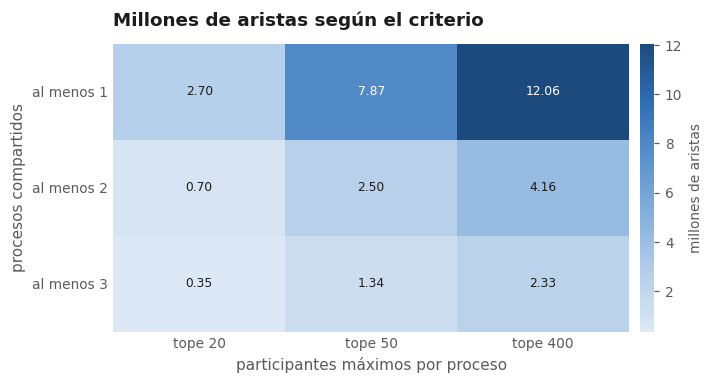

In [19]:
tabla = sens.pivot(index="minimo", columns="tope", values="aristas")
tabla.index = [f"al menos {m}" for m in tabla.index]; tabla.columns = [f"tope {t}" for t in tabla.columns]
fig, ax = mapa_calor(tabla / 1e6, "Millones de aristas según el criterio", "millones de aristas", "{:.2f}")
fig.set_size_inches(6.4, 3.4)
ax.set_xlabel("participantes máximos por proceso"); ax.set_ylabel("procesos compartidos")
s = sens.set_index(["tope", "minimo"])
figura(fig, "f05_sensibilidad_grafo", f"""
El criterio que más pesa no es el tope sino el mínimo de procesos compartidos. Con una sola
coincidencia el grafo tiene {s.loc[(400, 1), 'aristas']/1e6:.1f} millones de aristas; exigir dos
lo baja a {s.loc[(400, 2), 'aristas']/1e6:.2f} millones, porque la gran mayoría de pares de
competidores se cruzó una sola vez. Eso es una buena noticia para la pregunta 3: coincidir
repetidamente es raro, y por eso mismo es una señal. Se adopta tope 50 y mínimo 2, con
{s.loc[(50, 2), 'aristas']:,} aristas y {s.loc[(50, 2), 'nodos']:,} nodos: un grafo que conserva
las relaciones repetidas y cabe en memoria de una sola máquina para los métodos exactos.""")

In [20]:
TOPE, MINIMO = 50, 2
aristas = R.aristas_coparticipacion(part_r, TOPE, MINIMO)
aristas.write.mode("overwrite").parquet(str(BASE / "grafo_aristas"))
aristas = spark.read.parquet(str(BASE / "grafo_aristas"))
grado = (aristas.select(F.col("src").alias("nodo"), "peso").union(aristas.select("dst", "peso"))
         .groupBy("nodo").agg(F.count("*").alias("grado"), F.sum("peso").alias("fuerza")))
participa = part_r.groupBy("nodo").agg(F.countDistinct("ocid").alias("participaciones"))
nodos = (grado.join(mapa_proveedores.select("nodo", "clave", "nombre", "tipo").dropDuplicates(["nodo"]), "nodo")
         .join(participa, "nodo")
         .join(feat_prov.select("nodo", "n_ganados", "monto_total"), "nodo", "left")
         .fillna(0, subset=["n_ganados", "monto_total"]))
nodos.write.mode("overwrite").parquet(str(BASE / "grafo_nodos"))
nodos = spark.read.parquet(str(BASE / "grafo_nodos"))
pares_todos.unpersist()

ar = aristas.toPandas()
from scipy import sparse
from scipy.sparse.csgraph import connected_components
ids = pd.Index(np.unique(np.r_[ar.src.values, ar.dst.values]))
A = sparse.coo_matrix((np.ones(len(ar)), (ids.get_indexer(ar.src), ids.get_indexer(ar.dst))),
                      shape=(len(ids), len(ids)))
n_comp, etiqueta = connected_components(A, directed=False)
tam = np.bincount(etiqueta)
gigante = tam.max() / len(ids)
g = np.asarray((A + A.T).sum(1)).ravel()
grafo_res = pd.DataFrame([{"nodos": len(ids), "aristas": len(ar), "componentes": n_comp,
                           "pct_componente_gigante": round(100 * gigante, 1),
                           "grado_medio": round(g.mean(), 1), "grado_max": int(g.max()),
                           "repeticion_max": int(ar.procesos.max())}])
exportar(grafo_res, "p1_grafo", "Resumen del grafo de coparticipacion adoptado")
grafo_res

,nodos,aristas,componentes,pct_componente_gigante,grado_medio,grado_max,repeticion_max
0,70383,2498491,682,97.4,71.0,13717,2590



Lectura de f06_grafo_coparticipacion
El grafo tiene 70,383 proveedores y 2,498,491 aristas, y su componente gigante reúne al 97 por ciento de los nodos: la competencia en el Estado peruano forma una sola red conectada, no islas. A la derecha, la mayoría de pares coincide dos o tres veces, pero 85,599 pares coincidieron en 20 procesos o más y el más repetido en 2,590. Esos conteos extremos no son por sí solos una señal: hay proveedores que se registran como participantes en miles de procesos, hasta 8,315 en tres años, y dos participantes masivos coinciden mucho por pura frecuencia. Por eso la sección siguiente no ordena los pares por conteo sino por afinidad.



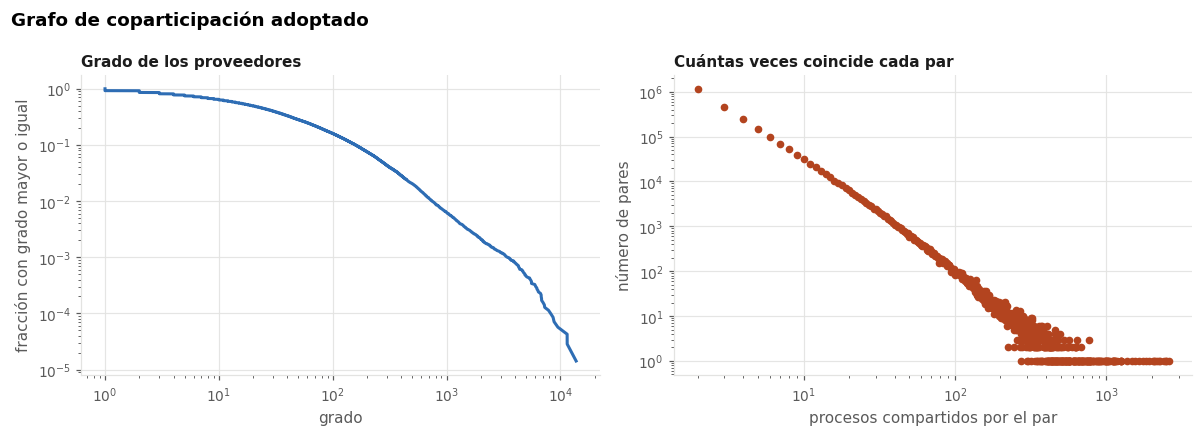

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.sort(g); y = 1 - np.arange(len(x)) / len(x)
axes[0].loglog(x, y, color=AZUL, lw=2)
axes[0].set_xlabel("grado"); axes[0].set_ylabel("fracción con grado mayor o igual")
axes[0].set_title("Grado de los proveedores", loc="left", fontsize=10)
rep = ar.procesos.value_counts().sort_index()
axes[1].loglog(rep.index, rep.values, "o", color=ROJO, ms=4)
axes[1].set_xlabel("procesos compartidos por el par"); axes[1].set_ylabel("número de pares")
axes[1].set_title("Cuántas veces coincide cada par", loc="left", fontsize=10)
for ax in axes: ax.grid(alpha=.9); ax.set_axisbelow(True)
fig.suptitle("Grafo de coparticipación adoptado", x=.01, ha="left", fontweight="bold"); fig.tight_layout()
top_par = ar.nlargest(1, "procesos").iloc[0]
muchos = (ar.procesos >= 20).sum()
part_max = nodos.agg(F.max("participaciones")).first()[0]
figura(fig, "f06_grafo_coparticipacion", f"""
El grafo tiene {len(ids):,} proveedores y {len(ar):,} aristas, y su componente gigante reúne al
{100*gigante:.0f} por ciento de los nodos: la competencia en el Estado peruano forma una sola red
conectada, no islas. A la derecha, la mayoría de pares coincide dos o tres veces, pero {muchos:,}
pares coincidieron en 20 procesos o más y el más repetido en {int(top_par.procesos):,}. Esos conteos
extremos no son por sí solos una señal: hay proveedores que se registran como participantes en
miles de procesos, hasta {part_max:,} en tres años, y dos participantes masivos coinciden mucho por
pura frecuencia. Por eso la sección siguiente no ordena los pares por conteo sino por afinidad.""")

**De la coincidencia a la afinidad.** Para que el conteo signifique algo hay que compararlo con lo que cada proveedor participa. La afinidad de un par es la fracción de las participaciones del menos activo de los dos que ocurrieron junto al otro: procesos compartidos dividido entre el mínimo de sus participaciones, el coeficiente de solapamiento. Una afinidad de 0,9 con 30 procesos dice que, de las 33 veces que el menos activo se presentó, en 30 estuvo el otro. Se exigen al menos 10 procesos compartidos para no premiar pares de dos o tres coincidencias.


Lectura de f07_afinidad_pares
De los 241,166 pares que coincidieron en 10 procesos o más, la mayoría tiene afinidad baja: se cruzan porque los dos participan mucho. Pero 4,847 pares, en rojo, tienen afinidad de 0,8 o más: cuando el menos activo de los dos se presenta, el otro está ahí al menos cuatro de cada cinco veces. Ese patrón, dos proveedores que se presentan juntos casi siempre, es el que las guías de competencia asocian a ofertas de acompañamiento, y también el de dos empresas vinculadas o de un mercado regional con dos oferentes. El grafo no distingue entre esas explicaciones; sí reduce la lista a los pares que vale la pena revisar a mano.


HALLAZGO. Hay pares de proveedores que se presentan juntos casi siempre
Ordenar por conteo de coincidencias solo encuentra a los participantes masivos. Medido como afinidad, 4,847 pares con al menos 10 procesos compartidos coinciden en el 80 por ciento o más de las participaciones del menos activo. Es una señal descriptiva con explicacion

,proveedor_a,proveedor_b,procesos,pa,pb,afinidad
130124,GRUPO 3A CONSULTORIA & CONSTRUCCIONES S.A.C.,JATUN SACHA E.I.R.L,1742,1946,2300,0.895
175639,GIL VELASQUEZ JUAN MANUEL,ARAUJO GUEVARA JUAN CARLOS,1147,1375,1415,0.834
141376,PROFESIONALES ASOCIADOS EN SERVICIOS DE CALIDAD QNC-PASEC QN...,TVT QONTRATISTAS E.I.R.L.,1057,1190,8315,0.888
91252,SUDAMERICANA LOGISTICA HISUKI SOCIEDAD ANONIMA CERRADA,MELTZER INTERNATIONAL SOCIEDAD ANONIMA CERRADA,1016,1771,1222,0.831
90155,AUTOMOTRIZ SAN BLAS S.A.,CHALSA CORPORATION S.A.C.,993,1117,2327,0.889
89921,JN VIRDCO S.A.C,FORZAMAT S.A.C.,987,3422,1202,0.821
89956,COMERCIAL FERRETERIA FATIMA SOCIEDAD ANONIMA CERRADA - COMER...,GRUPO SANTA FE SOCIEDAD ANONIMA CERRADA - GRUPO SANTA FE S.A.C.,946,1021,3290,0.927
121223,CORPORACION CLABE S.R.L.,GRUPO SANTA FE SOCIEDAD ANONIMA CERRADA - GRUPO SANTA FE S.A.C.,779,916,3290,0.850
104649,VERA USCA KARINA,JN VIRDCO S.A.C,756,795,3422,0.951
489,CHALSA CORPORATION S.A.C.,AUTONIZA S.A.C.,681,2327,748,0.910


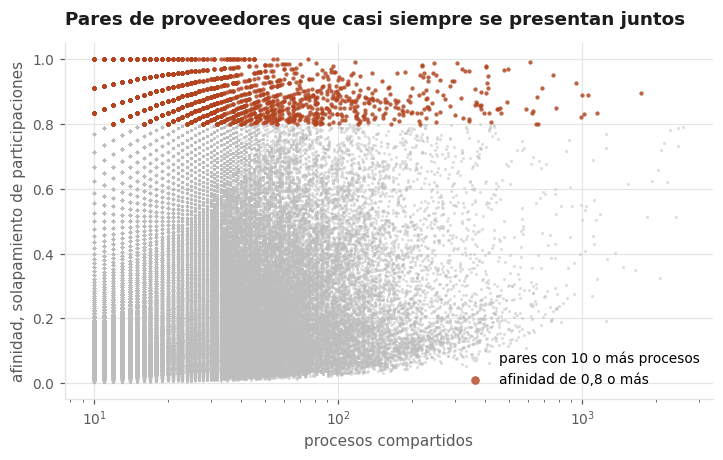

In [22]:
participa_nodo = nodos.select("nodo", "participaciones", "nombre")
afinidad = (aristas.filter("procesos >= 10")
            .join(participa_nodo.select(F.col("nodo").alias("src"), F.col("participaciones").alias("pa"),
                                        F.col("nombre").alias("proveedor_a")), "src")
            .join(participa_nodo.select(F.col("nodo").alias("dst"), F.col("participaciones").alias("pb"),
                                        F.col("nombre").alias("proveedor_b")), "dst")
            .withColumn("afinidad", F.col("procesos") / F.least("pa", "pb"))).toPandas()
inseparables = afinidad[afinidad.afinidad >= .8]
pares_rep = (inseparables.sort_values(["procesos"], ascending=False)
             [["proveedor_a", "proveedor_b", "procesos", "pa", "pb", "afinidad"]].head(15).round(3))
exportar(pares_rep, "p1_pares_afines", "Pares de proveedores que casi siempre participan juntos")

fig, ax = plt.subplots(figsize=(7.6, 4.2))
# Los puntos se rasterizan dentro del SVG: son 245 mil y como vectores el archivo
# pesaria decenas de MB. Ejes, texto y leyenda siguen siendo vectoriales.
ax.scatter(afinidad.procesos, afinidad.afinidad, s=4, color="#BDBDBD", alpha=.5, lw=0,
           label="pares con 10 o más procesos", rasterized=True)
ax.scatter(inseparables.procesos, inseparables.afinidad, s=8, color=ROJO, alpha=.8, lw=0,
           label="afinidad de 0,8 o más", rasterized=True)
ax.set_xscale("log"); ax.set_xlabel("procesos compartidos"); ax.set_ylabel("afinidad, solapamiento de participaciones")
ax.set_title("Pares de proveedores que casi siempre se presentan juntos", loc="left", pad=12)
ax.grid(alpha=.9); ax.set_axisbelow(True); ax.legend(loc="lower right", markerscale=2)
figura(fig, "f07_afinidad_pares", f"""
De los {len(afinidad):,} pares que coincidieron en 10 procesos o más, la mayoría tiene afinidad baja:
se cruzan porque los dos participan mucho. Pero {len(inseparables):,} pares, en rojo, tienen afinidad
de 0,8 o más: cuando el menos activo de los dos se presenta, el otro está ahí al menos cuatro de cada
cinco veces. Ese patrón, dos proveedores que se presentan juntos casi siempre, es el que las guías de
competencia asocian a ofertas de acompañamiento, y también el de dos empresas vinculadas o de un
mercado regional con dos oferentes. El grafo no distingue entre esas explicaciones; sí reduce la
lista a los pares que vale la pena revisar a mano.""")

hallazgo("I", "Hay pares de proveedores que se presentan juntos casi siempre",
         f"""Ordenar por conteo de coincidencias solo encuentra a los participantes masivos. Medido como
         afinidad, {len(inseparables):,} pares con al menos 10 procesos compartidos coinciden en el 80 por
         ciento o más de las participaciones del menos activo. Es una señal descriptiva con explicaciones
         legítimas posibles, como empresas vinculadas o un mercado con dos oferentes.""",
         """Usar estos pares como cola de revisión del área de competencia, cruzando para cada uno quién
         gana cuando se presentan juntos y si el perdedor alguna vez gana solo; las Partes IV y V los
         ubicarán dentro de sus comunidades.""",
         "f07_afinidad_pares, p1_pares_afines")
pares_rep

## 8. Particionamiento y plan de ejecución

Tres decisiones de particionado del notebook, cada una con su plan físico y su costo medido.

**Particionado en disco por año.** La tabla de hechos se escribió con partitionBy de anio, que crea una carpeta por año. Un filtro por año se convierte en un PartitionFilter: Spark ni siquiera abre los archivos de los otros años.

In [23]:
solo_2025 = spark.read.parquet(str(BASE / "hechos")).filter("anio = 2025")
plan = solo_2025._jdf.queryExecution().executedPlan().toString()
print([l.strip()[:160] for l in plan.split("\n") if "PartitionFilters" in l][0])
t_todo = medir(lambda: spark.read.parquet(str(BASE / "hechos")).groupBy("familia").count().collect())
t_2025 = medir(lambda: solo_2025.groupBy("familia").count().collect())
print(f"agregado sobre los tres años: {t_todo:.2f} s, solo 2025 con poda de particiones: {t_2025:.2f} s")

+- FileScan parquet [ocid#7189,awards_id#7190,comprador_id#7191,clave#7192,nodo#7193L,tipo#7194,familia#7195,monto#7196,fecha#7197,anio_mes#7198,metodo#7199,cat


agregado sobre los tres años: 0.20 s, solo 2025 con poda de particiones: 0.15 s


**Broadcast frente a sort merge.** Al unir los hechos con la tabla de entidades, que es pequeña, Spark elige por sí solo un BroadcastHashJoin: copia la tabla pequeña a cada tarea y evita barajar la grande. Se fuerza la alternativa, un SortMergeJoin, para ver lo que cuesta barajar los dos lados.

In [24]:
entidades = (spark.read.parquet(str(BASE / "caracteristicas_entidades"))
             .select("comprador_id", F.col("n_proveedores").alias("tamano_cartera")))
consulta = lambda: (hechos.join(entidades, "comprador_id")
                    .groupBy((F.col("tamano_cartera") > 100).alias("cartera_grande")).agg(F.sum("monto")).collect())

def tipo_join():
    p = hechos.join(entidades, "comprador_id")._jdf.queryExecution().executedPlan().toString()
    return "BroadcastHashJoin" if "BroadcastHashJoin" in p else "SortMergeJoin"

print("plan por omisión:", tipo_join())
t_broadcast = medir(consulta)
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")
spark.conf.set("spark.sql.adaptive.enabled", "false")
print("plan forzado:   ", tipo_join())
t_sortmerge = medir(consulta)
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", str(10 * 1024 * 1024))
spark.conf.set("spark.sql.adaptive.enabled", "true")
print(f"broadcast {t_broadcast:.2f} s, sort merge {t_sortmerge:.2f} s")

plan por omisión: BroadcastHashJoin


plan forzado:    SortMergeJoin


broadcast 0.28 s, sort merge 0.36 s


**Particiones de barajado en el autojoin del grafo.** El autojoin de participaciones por ocid es el paso más caro del notebook: un Exchange hashpartitioning por ocid reparte los participantes de cada proceso a la misma partición, y ahí se forman los pares. El número de particiones de ese barajado se mide con la adaptación de consultas apagada, para que Spark no lo corrija por su cuenta y la diferencia se vea.

In [25]:
def armar_grafo():
    return R.aristas_coparticipacion(part_r, TOPE, MINIMO).count()

plan = R.aristas_coparticipacion(part_r, TOPE, MINIMO)._jdf.queryExecution().executedPlan().toString()
print([l.strip()[:120] for l in plan.split("\n") if "Exchange hashpartitioning" in l][:2])

spark.conf.set("spark.sql.adaptive.enabled", "false")
tiempos = []
for p in [1, 8, 64, 200]:
    spark.conf.set("spark.sql.shuffle.partitions", p)
    tiempos.append({"particiones": p, "segundos": round(medir(armar_grafo, 1), 2)})
spark.conf.set("spark.sql.shuffle.partitions", 8)
spark.conf.set("spark.sql.adaptive.enabled", "true")
tiempos = pd.DataFrame(tiempos)
plan_tabla = pd.DataFrame([
    {"decision": "lectura con poda por año", "segundos": round(t_2025, 2)},
    {"decision": "lectura de los tres años", "segundos": round(t_todo, 2)},
    {"decision": "join con broadcast", "segundos": round(t_broadcast, 2)},
    {"decision": "join con sort merge", "segundos": round(t_sortmerge, 2)}])
exportar(tiempos, "p1_particiones", "Tiempo del autojoin del grafo segun particiones de barajado")
exportar(plan_tabla, "p1_plan", "Tiempo de las decisiones de particionado y de join")
tiempos

['+- Exchange hashpartitioning(src#24557L, dst#24558L, 8), ENSURE_REQUIREMENTS, [plan_id=30875]', ':     :  +- Exchange hashpartitioning(ocid#7291, 8), ENSURE_REQUIREMENTS, [plan_id=30854]']


,particiones,segundos
0,1,41.06
1,8,15.23
2,64,16.10
3,200,15.60



Lectura de f08_particiones
La única diferencia robusta es la de una sola partición: 41.1 segundos, 2.7 veces el mejor caso, porque toda la agregación de pares queda en un solo hilo. Entre 8, 64 y 200 particiones los tiempos van de 15.2 a 16.1 segundos, una diferencia de 6 por ciento, y el orden entre ellas cambió de una corrida a otra: la máquina estaba compartida con otro trabajo y esa variación es del mismo tamaño que la carga. Lo que sí se sostiene es el criterio: hacen falta al menos tantas particiones como hilos para usar el paralelismo, y más allá de eso el costo fijo de programar cientos de tareas pequeñas solo se paga si las particiones son grandes. La sesión usa 8, 15.2 segundos en esta corrida, con la ejecución adaptativa encendida para que Spark fusione particiones pequeñas por su cuenta. Las otras dos decisiones sí dan diferencias claras: la poda por año lee 1.4 veces más rápido y el broadcast es 1.3 veces más rápido que el sort merge.



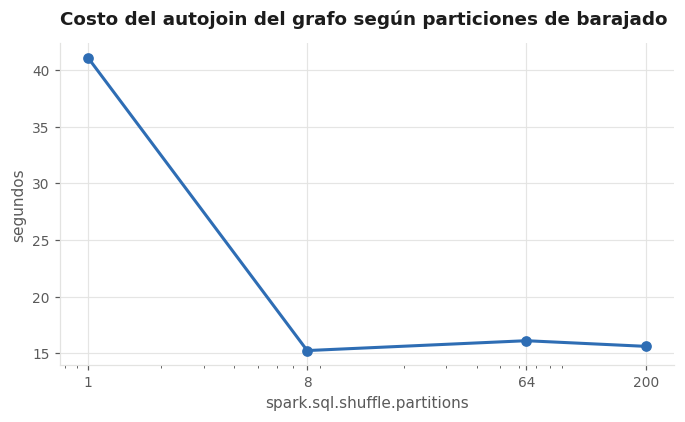

In [26]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.plot(tiempos.particiones, tiempos.segundos, "o-", color=AZUL, lw=2)
ax.set_xscale("log"); ax.set_xticks(tiempos.particiones, tiempos.particiones)
ax.set_xlabel("spark.sql.shuffle.partitions"); ax.set_ylabel("segundos")
ax.set_title("Costo del autojoin del grafo según particiones de barajado", loc="left", pad=12)
ax.grid(alpha=.9); ax.set_axisbelow(True)
mejor = tiempos.loc[tiempos.segundos.idxmin()]
peor = tiempos.loc[tiempos.segundos.idxmax()]
una = tiempos.set_index("particiones").segundos[1]
resto = tiempos[tiempos.particiones > 1]
dispersion = resto.segundos.max() / resto.segundos.min()
ocho = tiempos.set_index("particiones").segundos[8]
figura(fig, "f08_particiones", f"""
La única diferencia robusta es la de una sola partición: {una:.1f} segundos, {una / resto.segundos.min():.1f}
veces el mejor caso, porque toda la agregación de pares queda en un solo hilo. Entre 8, 64 y 200
particiones los tiempos van de {resto.segundos.min():.1f} a {resto.segundos.max():.1f} segundos, una
diferencia de {100*(dispersion - 1):.0f} por ciento, y el orden entre ellas cambió de una corrida a otra:
la máquina estaba compartida con otro trabajo y esa variación es del mismo tamaño que la carga. Lo que
sí se sostiene es el criterio: hacen falta al menos tantas particiones como hilos para usar el
paralelismo, y más allá de eso el costo fijo de programar cientos de tareas pequeñas solo se paga si
las particiones son grandes. La sesión usa 8, {ocho:.1f} segundos en esta corrida, con la ejecución
adaptativa encendida para que Spark fusione particiones pequeñas por su cuenta. Las otras dos
decisiones sí dan diferencias claras: la poda por año lee {t_todo / max(t_2025, 1e-9):.1f} veces más
rápido y el broadcast es {t_sortmerge / max(t_broadcast, 1e-9):.1f} veces más rápido que el sort merge.""")

## 9. Lo que queda listo para las partes siguientes

In [27]:
import os
def tamano(ruta):
    return sum(f.stat().st_size for f in Path(ruta).rglob("*.parquet")) / 1e6

catalogo = [
    ("hechos", "adjudicación y proveedor resuelto, particionado por año", "todas"),
    ("participaciones", "proceso y participante resuelto", "IV, V"),
    ("mapa_proveedores", "identificador publicado y su clave resuelta", "todas"),
    ("caracteristicas_proveedores", "un vector por proveedor", "II, VI"),
    ("caracteristicas_entidades", "un vector por entidad", "II, IV"),
    ("interaccion_entidad_proveedor", "entidad, proveedor, año, adjudicaciones y monto", "III, IV"),
    ("interaccion_entidad_familia", "entidad, familia CUBSO, año, adjudicaciones y monto", "III, VI"),
    ("grafo_nodos", "proveedor con grado y fuerza", "IV, V, VI"),
    ("grafo_aristas", "par de proveedores, procesos compartidos y peso de Newman", "IV, V, VI"),
]
salida = pd.DataFrame([{"tabla": t, "contenido": c, "filas": spark.read.parquet(str(BASE / t)).count(),
                        "mb": round(tamano(BASE / t), 2), "lo_usa_la_parte": u} for t, c, u in catalogo])
exportar(salida, "p1_catalogo", "Tablas de la base relacional exportadas por la Parte I")
exportar(pd.DataFrame(FIGURAS), "p1_figuras", "Figuras de la Parte I con su lectura")
exportar(pd.DataFrame(HALLAZGOS), "p1_hallazgos", "Hallazgos de la Parte I con su accion propuesta")
salida

,tabla,contenido,filas,mb,lo_usa_la_parte
0,hechos,"adjudicación y proveedor resuelto, particionado por año",154591,8.78,todas
1,participaciones,proceso y participante resuelto,2221884,33.90,"IV, V"
2,mapa_proveedores,identificador publicado y su clave resuelta,209207,7.89,todas
3,caracteristicas_proveedores,un vector por proveedor,62462,3.44,"II, VI"
4,caracteristicas_entidades,un vector por entidad,2968,0.16,"II, IV"
5,interaccion_entidad_proveedor,"entidad, proveedor, año, adjudicaciones y monto",124188,2.32,"III, IV"
6,interaccion_entidad_familia,"entidad, familia CUBSO, año, adjudicaciones y monto",54903,0.51,"III, VI"
7,grafo_nodos,proveedor con grado y fuerza,70383,3.72,"IV, V, VI"
8,grafo_aristas,"par de proveedores, procesos compartidos y peso de Newman",2498491,26.98,"IV, V, VI"


**Cierre.** La base relacional queda en data/processed, en Parquet, y lo único que las partes siguientes necesitan de este notebook son esas tablas. Tres resultados de esta parte cambian lo que se puede concluir después:

1. **La identidad del proveedor no era confiable.** La mitad de los identificadores publicados son códigos de consorcio, y la validación con el propio dato mostró que ni el nombre basta para fusionarlos. Todo ranking o medida de concentración posterior usa la clave resuelta.
2. **El mercado se renueva.** Tres de cada cuatro relaciones de un año son nuevas, aunque las repetidas pesan más en monto. Anticipar la relación nueva es el trabajo del recomendador, y la relación nueva e improbable es la señal interesante.
3. **Coincidir repetidamente es raro, y coincidir casi siempre lo es aún más.** El grafo con mínimo de dos procesos conserva las relaciones repetidas, y la afinidad separa a los pares que se presentan juntos casi siempre de los participantes masivos que coinciden por pura frecuencia.

In [28]:
spark.stop()